# Lagos Property Data — EDA & Visualisation
**Project steps 3 and 4: Exploratory Data Analysis and Data Visualisation**

Input: `lagos_properties_clean.csv` (from `02_data_cleaning.ipynb`)



**Important:** Sale and Rent prices are completely different markets (₦200M to buy vs ₦5M a year to rent), so they are **always analysed separately**.

## 1. Import libraries and load the clean data

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
os.makedirs("charts", exist_ok=True)      # every chart is also saved here for the report

df = pd.read_csv("lagos_properties_clean.csv")
print(df.shape)
df.head()

(1973, 23)


,listing_id,listing_type,title,property_type,property_group,property_category,price_ngn,price_ngn_m,price_per_bedroom,currency_original,...,toilets,parking,neighbourhood,area,region,location,is_multi_unit,is_outlier,url,scraped_on
0,3388814,Sale,Newly Built 4 Bedroom Fully Detached Bungalow,Detached bungalow,Bungalow,Residential,100000000,100.0,25000000.0,NGN,...,5.0,3,Igando Orudu,Ibeju Lekki,Island,"Igando Orudu, Ibeju Lekki, Lagos",False,False,https://nigeriapropertycentre.com/for-sale/hou...,2026-10-10
1,3087107,Sale,Land,Residential land,Land,Land,50000000,50.0,NaN,NGN,...,NaN,5,10Mins Drive To Command Off Ikola Road,Ipaja,Mainland,"Mainland Heritage, 10mins Drive to Command Off...",False,False,https://nigeriapropertycentre.com/for-sale/lan...,2026-10-10
2,3715040,Sale,Residential Land Plot Fenced,Residential land,Land,Land,75000000,75.0,NaN,NGN,...,NaN,0,Alapere,Ketu,Mainland,"Off Ezobi Street, Alapere, Ketu, Lagos",False,False,https://nigeriapropertycentre.com/for-sale/lan...,2026-10-10
3,3663484,Sale,4 Bedroom Detached Duplex,Detached duplex,Duplex,Residential,280000000,280.0,70000000.0,NGN,...,5.0,0,Idado,Lekki,Island,"Idado, Lekki, Lagos",False,False,https://nigeriapropertycentre.com/for-sale/hou...,2026-10-10
4,3693891,Sale,Best Value 3 Bedroom Self Compound Terraced Du...,Terraced duplex,Duplex,Residential,115000000,115.0,38333333.0,NGN,...,4.0,2,Sangotedo,Ajah,Island,"Within a Gated, Very Secured Estate with No Fl...",False,False,https://nigeriapropertycentre.com/for-sale/hou...,2026-10-10


## 2. Create the subsets we will analyse
- **sale** = all listings for sale, **rent** = all listings for rent.
- **sale_homes / rent_homes** = residential homes only (no land, no commercial, no 9+ room blocks), with outliers removed. These give a fair picture of a *normal* home's price.

In [2]:
sale = df[df["listing_type"] == "Sale"]
rent = df[df["listing_type"] == "Rent"]

def normal_homes(data):
    return data[(data["property_category"] == "Residential")
                & (data["is_multi_unit"] == False)
                & (data["is_outlier"] == False)]

sale_homes = normal_homes(sale)
rent_homes = normal_homes(rent)

print("For sale:", len(sale), "| normal homes for sale:", len(sale_homes))
print("For rent:", len(rent), "| normal homes for rent:", len(rent_homes))

For sale: 1000 | normal homes for sale: 837
For rent: 973 | normal homes for rent: 911


## 3. Summary statistics (mean, median, mode)

In [3]:
def price_summary(data, label):
    p = data["price_ngn_m"]
    print(f"--- {label} ---")
    print(f"Mean:    ₦{p.mean():,.1f}M")
    print(f"Median:  ₦{p.median():,.1f}M")
    print(f"Mode:    ₦{p.mode()[0]:,.1f}M")
    print(f"Min:     ₦{p.min():,.1f}M")
    print(f"Max:     ₦{p.max():,.1f}M\n")

price_summary(sale, "SALE price (all listings)")
price_summary(rent, "RENT price per year (all listings)")

--- SALE price (all listings) ---
Mean:    ₦924.9M
Median:  ₦350.0M
Mode:    ₦350.0M
Min:     ₦5.0M
Max:     ₦32,000.0M

--- RENT price per year (all listings) ---
Mean:    ₦22.7M
Median:  ₦13.0M
Mode:    ₦15.0M
Min:     ₦0.2M
Max:     ₦320.0M



In [4]:
print("Most common area:          ", df["area"].mode()[0])
print("Most common property group:", df["property_group"].mode()[0])
print("Most common bedroom count: ", df["bedrooms"].mode()[0])

df[["price_ngn_m", "bedrooms", "bathrooms", "toilets", "parking"]].describe().round(1)

Most common area:           Lekki
Most common property group: Flat / Apartment
Most common bedroom count:  4.0


,price_ngn_m,bedrooms,bathrooms,toilets,parking
count,1973.0,1790.0,1799.0,1812.0,1973.0
mean,480.0,3.6,3.7,4.4,2.4
std,1522.8,3.6,3.8,4.1,40.6
min,0.2,1.0,1.0,1.0,0.0
25%,13.0,2.0,2.0,3.0,0.0
50%,75.0,3.0,3.0,4.0,0.0
75%,350.0,4.0,4.0,5.0,2.0
max,32000.0,70.0,71.0,96.0,1800.0


**What this shows:** the **mean** is far above the **median** for both sale and rent. A few very expensive Ikoyi/VI properties pull the average up, so the **median is the better "typical price"** and is used for the rest of the analysis.

## 4. Correlations between numerical columns
Using normal homes for sale. A value close to **1** means "both go up together"; close to **0** means "no relationship".

In [5]:
num_cols = ["price_ngn_m", "bedrooms", "bathrooms", "toilets", "parking"]
corr = sale_homes[num_cols].corr().round(2)
corr

,price_ngn_m,bedrooms,bathrooms,toilets,parking
price_ngn_m,1.00,0.42,0.39,0.37,-0.01
bedrooms,0.42,1.00,0.90,0.91,-0.01
bathrooms,0.39,0.90,1.00,0.93,0.01
toilets,0.37,0.91,0.93,1.00,0.02
parking,-0.01,-0.01,0.01,0.02,1.00


In [6]:
print("Bedrooms vs price: ", corr.loc["bedrooms", "price_ngn_m"])
print("Bathrooms vs price:", corr.loc["bathrooms", "price_ngn_m"])
print("Bedrooms vs bathrooms:", corr.loc["bedrooms", "bathrooms"])

Bedrooms vs price:  0.42
Bathrooms vs price: 0.39
Bedrooms vs bathrooms: 0.9


## 5. Outliers and anomalies
Outliers were flagged during cleaning with the IQR method (`is_outlier` column). They are **real** listings (luxury mansions, hotels, large land), so they are kept but analysed separately.

In [7]:
print("Outliers by listing type:")
print(df.groupby("listing_type")["is_outlier"].sum(), "\n")

print("Top 10 most expensive listings for sale:")
sale.sort_values("price_ngn_m", ascending=False)[
    ["title", "property_group", "area", "price_ngn_m", "is_outlier"]].head(10)

Outliers by listing type:
listing_type
Rent     8
Sale    23
Name: is_outlier, dtype: int64 

Top 10 most expensive listings for sale:


,title,property_group,area,price_ngn_m,is_outlier
861,Block of 36 Flats with 4 Bedrooms Each,Flat / Apartment,Ikoyi,32000.0,True
324,"38,752SQM Parcel of Land",Land,Ikeja,25000.0,True
959,Luxury 12 Units of 3 Bed Apartment and 1 Unit ...,Flat / Apartment,Ikoyi,22644.0,True
418,Well Developed 5 Bedroom Detached House,Duplex,Ikoyi,13320.0,True
796,Commercial Property,Commercial,Ifako-Ijaiye,12500.0,True
74,A Well Built Industrial Warehouse + Office Block,Commercial,Surulere,12000.0,True
161,"Land Measuring 4,100SQM [video Available on Re...",Land,Ikeja,12000.0,True
900,About 70 Rooms Luxury Hotel,Commercial,Victoria Island,10000.0,True
361,7 Hectares of Land Water Front,Land,Ibeju Lekki,10000.0,True
576,Premium 6-Bedrooms Penthouse Maisonette,Flat / Apartment,Ikoyi,9990.0,True


In [8]:
# Anomaly check: homes with an unusually high price PER BEDROOM
ppb = sale_homes["price_per_bedroom"] / 1_000_000
print(f"Median price per bedroom: ₦{ppb.median():.1f}M")
print(f"Highest price per bedroom: ₦{ppb.max():.1f}M")

sale_homes.assign(price_per_bed_m=ppb).sort_values("price_per_bed_m", ascending=False)[
    ["title", "area", "bedrooms", "price_ngn_m", "price_per_bed_m"]].head(5)

Median price per bedroom: ₦100.0M
Highest price per bedroom: ₦2000.0M


,title,area,bedrooms,price_ngn_m,price_per_bed_m
442,"9 Units of 3 Bedroom Apartments, 2 Units of 3 ...",Ikeja,3.0,6000.0,2000.000000
572,15 Unit of Apartment Mini Estate,Victoria Island,3.0,4500.0,1500.000000
123,6 Bedroom Detached House with BQ and Swimming ...,Ikoyi,6.0,8000.0,1333.333333
709,4 Units of Newly Built Spacious 5 Bedroom Full...,Ikoyi,5.0,6660.0,1332.000000
262,Fully Detached Mansion on 700 Square Meters,Ikoyi,5.0,6660.0,1332.000000


## 6. Group-by analysis

### 6.1 By area — which areas are most expensive?
Only areas with at least 10 listings, so the medians are fair.

In [9]:
def by_group(data, column, min_count=10):
    g = data.groupby(column)["price_ngn_m"].agg(["count", "median", "mean"]).round(1)
    return g[g["count"] >= min_count].sort_values("median", ascending=False)

sale_by_area = by_group(sale_homes, "area")
rent_by_area = by_group(rent_homes, "area")
print("SALE — median price by area (₦M)")
sale_by_area

SALE — median price by area (₦M)


,count,median,mean
area,,,
Ikoyi,108,2039.0,2694.4
Victoria Island,53,601.1,908.0
Ikeja,60,450.0,675.6
Magodo,20,440.0,501.2
Lekki,383,350.0,524.6
Gbagada,41,330.0,309.9
Maryland,10,315.0,358.5
Surulere,14,235.0,276.1
Ajah,70,155.0,211.0


In [10]:
print("RENT — median yearly rent by area (₦M)")
rent_by_area

RENT — median yearly rent by area (₦M)


,count,median,mean
area,,,
Ikoyi,138,46.5,61.4
Victoria Island,64,30.0,35.2
Ikeja,36,20.0,22.4
Lekki,478,12.0,14.5
Magodo,19,6.5,8.3
Surulere,15,5.0,6.2
Ajah,98,4.0,4.9
Ibeju Lekki,11,2.0,2.9


### 6.2 By property group

In [11]:
sale_by_group = by_group(sale[sale["is_outlier"] == False], "property_group", min_count=5)
sale_by_group

,count,median,mean
property_group,,,
Commercial,17,800.0,1015.9
House,36,460.0,1344.1
Duplex,507,420.0,863.0
Land,113,270.0,760.5
Flat / Apartment,292,260.0,565.7
Bungalow,12,100.0,162.3


### 6.3 Island vs Mainland

In [12]:
region = df[df["is_outlier"] == False].pivot_table(
    index="region", columns="listing_type", values="price_ngn_m", aggfunc="median").round(1)
region

listing_type,Rent,Sale
region,,
Island,15.0,370.0
Mainland,6.5,350.0


### 6.4 By number of bedrooms (the trend)
No dates are available (all listings were scraped on the same day), so the trend is analysed across **bedroom count** instead of time.

In [13]:
sale_by_beds = sale_homes[sale_homes["bedrooms"].between(1, 6)].groupby("bedrooms")["price_ngn_m"].median().round(1)
rent_by_beds = rent_homes[rent_homes["bedrooms"].between(1, 6)].groupby("bedrooms")["price_ngn_m"].median().round(1)

beds_trend = pd.DataFrame({"sale_median_M": sale_by_beds, "rent_median_M": rent_by_beds})
beds_trend

,sale_median_M,rent_median_M
bedrooms,,
1.0,150.0,3.0
2.0,180.0,9.0
3.0,220.0,15.0
4.0,310.0,25.0
5.0,740.0,30.0
6.0,1700.0,40.0


### 6.5 Price per bedroom by area (value for money)
Total price hides how much space buyers get. Dividing price by bedrooms shows what each bedroom costs in each area.
Uses clean sale listings (no outliers, no multi-unit blocks) in areas with at least 10 sale listings. Land and commercial listings have no bedrooms, so they drop out automatically.

In [14]:
sale_clean = sale[(sale["is_outlier"] == False) & (sale["is_multi_unit"] == False)]
area_counts = sale_clean["area"].value_counts()
big_areas = area_counts[area_counts >= 10].index

ppb_all = (sale_clean[sale_clean["area"].isin(big_areas)]
           .groupby("area")["price_per_bedroom"].median()
           .div(1_000_000).round(1)
           .sort_values(ascending=False))
ppb_by_area = ppb_all.head(7)          # top 7, used in Chart 3
print("Median sale price per bedroom by area (₦M):")
ppb_all

Median sale price per bedroom by area (₦M):


area
Ikoyi              450.0
Victoria Island    248.2
Ikeja              125.0
Magodo             115.0
Lekki               95.0
Gbagada             87.5
Surulere            87.5
Maryland            83.8
Ajah                45.6
Ibeju Lekki         31.8
Name: price_per_bedroom, dtype: float64

**What this shows:** a bedroom in **Ikoyi** costs a median of about **₦450M**, almost five times **Lekki (₦95M)** and roughly ten times **Ajah**. Buyers pay very different amounts for the same space depending on location, so location drives value more than size.

### 6.6 Rental yield by area (where renting out pays best)
**Gross rental yield** = median annual rent ÷ median sale price. It shows how much rent a property earns each year as a share of its price.
Uses residential homes (no outliers, no multi-unit blocks) in areas with **at least 10 sale and 10 rent listings**, so one listing cannot distort an area's result.
Note: sale and rent figures come from different properties, so this is a rough guide, not an exact return.

In [15]:
homes = df[(df["property_category"] == "Residential")
           & (df["is_outlier"] == False) & (df["is_multi_unit"] == False)]
g = homes.groupby(["area", "listing_type"])["price_ngn_m"].agg(["count", "median"]).unstack()
g.columns = ["rent_n", "sale_n", "rent_median", "sale_median"]
g = g[(g["sale_n"] >= 10) & (g["rent_n"] >= 10)].copy()
g["yield_pct"] = (g["rent_median"] / g["sale_median"] * 100).round(1)
g["region"] = homes.groupby("area")["region"].first().reindex(g.index)
yield_by_area = g.reset_index().sort_values("yield_pct", ascending=False)   # used in Chart 5
yield_by_area[["area", "region", "sale_median", "rent_median", "yield_pct"]]

,area,region,sale_median,rent_median,yield_pct
7,Victoria Island,Island,601.06,30.000,5.0
2,Ikeja,Mainland,450.00,20.000,4.4
4,Lekki,Island,350.00,12.000,3.4
0,Ajah,Island,155.00,4.000,2.6
3,Ikoyi,Island,2038.96,46.475,2.3
6,Surulere,Mainland,235.00,5.000,2.1
1,Ibeju Lekki,Island,100.00,2.000,2.0
5,Magodo,Mainland,440.00,6.500,1.5


**What this shows:** **Victoria Island (5.0%)** and **Ikeja (4.4%)** give landlords the best return on price. **Ikoyi**, the most expensive area, returns only about **2.3%**, because its sale prices are far higher than its rents. The priciest area is not the best investment for rental income.

## 7. Key insights (calculated automatically)

In [16]:
top_sale_area = sale_by_area.index[0]
top_rent_area = rent_by_area.index[0]
top_group = sale_by_group.index[0]

print(f"1. Most expensive area to BUY a home: {top_sale_area} (median ₦{sale_by_area['median'].iloc[0]}M)")
print(f"2. Most expensive area to RENT a home: {top_rent_area} (median ₦{rent_by_area['median'].iloc[0]}M a year)")
print(f"3. Most expensive property group to buy: {top_group} (median ₦{sale_by_group['median'].iloc[0]}M)")
print(f"4. Area with the most listings: {df['area'].value_counts().index[0]} "
      f"({df['area'].value_counts().iloc[0]} of {len(df)})")
print(f"5. Island vs Mainland (sale median): ₦{region.loc['Island', 'Sale']}M vs ₦{region.loc['Mainland', 'Sale']}M "
      f"→ Island is {region.loc['Island', 'Sale'] / region.loc['Mainland', 'Sale']:.1f}x more expensive")
print(f"6. Bedrooms vs sale price correlation: {corr.loc['bedrooms', 'price_ngn_m']}")
print(f"7. Each extra bedroom adds roughly ₦{sale_by_beds.diff().median():.0f}M to the median sale price")
print(f"8. Mean sale price is ₦{sale['price_ngn_m'].mean():,.0f}M but the median is only ₦{sale['price_ngn_m'].median():,.0f}M "
      f"→ prices are heavily skewed by luxury listings")
best_yield = yield_by_area.iloc[0]
ikoyi_yield = yield_by_area.set_index("area").loc["Ikoyi", "yield_pct"]
print(f"9. Price per bedroom: Ikoyi ₦{ppb_all.iloc[0]:,.0f}M vs Lekki ₦{ppb_all['Lekki']:,.0f}M "
      f"→ {ppb_all.iloc[0] / ppb_all['Lekki']:.1f}x more for the same space")
print(f"10. Best rental yield: {best_yield['area']} ({best_yield['yield_pct']}%), "
      f"while Ikoyi returns only {ikoyi_yield}%")

1. Most expensive area to BUY a home: Ikoyi (median ₦2039.0M)
2. Most expensive area to RENT a home: Ikoyi (median ₦46.5M a year)
3. Most expensive property group to buy: Commercial (median ₦800.0M)
4. Area with the most listings: Lekki (919 of 1973)
5. Island vs Mainland (sale median): ₦370.0M vs ₦350.0M → Island is 1.1x more expensive
6. Bedrooms vs sale price correlation: 0.42
7. Each extra bedroom adds roughly ₦90M to the median sale price
8. Mean sale price is ₦925M but the median is only ₦350M → prices are heavily skewed by luxury listings
9. Price per bedroom: Ikoyi ₦450M vs Lekki ₦95M → 4.7x more for the same space
10. Best rental yield: Victoria Island (5.0%), while Ikoyi returns only 2.3%


### Summary for the report

- **Most expensive area:** Ikoyi is the priciest area to both buy and rent (insights 1–2), with Victoria Island a distant second.
- **The Island premium is a rent story:** Island rents are well above Mainland rents, but median sale prices are almost the same (insight 5), because the Island includes both premium areas (Ikoyi) and lower-priced areas (Ajah, Ibeju Lekki).
- **Size matters, but location matters more:** price rises with bedrooms (insight 7), but a bedroom in Ikoyi costs almost five times one in Lekki (insight 9).
- **Best rental returns are not in the priciest area:** Victoria Island and Ikeja offer the highest gross rental yields, while Ikoyi's yield is among the lowest (insight 10).
- **Skewed market:** a small number of luxury listings make the mean much higher than the median, so medians are used throughout (insight 8).
- **Data concentration:** Lekki accounts for nearly half of all listings (insight 4), which partly reflects how the data was collected.
- **Limitation:** all listings were scraped on one day, so no time or seasonal trend is possible.

# 8. Data Visualisation (9 charts, 8 different types)

### Chart 1 — Bar chart: median sale price by area

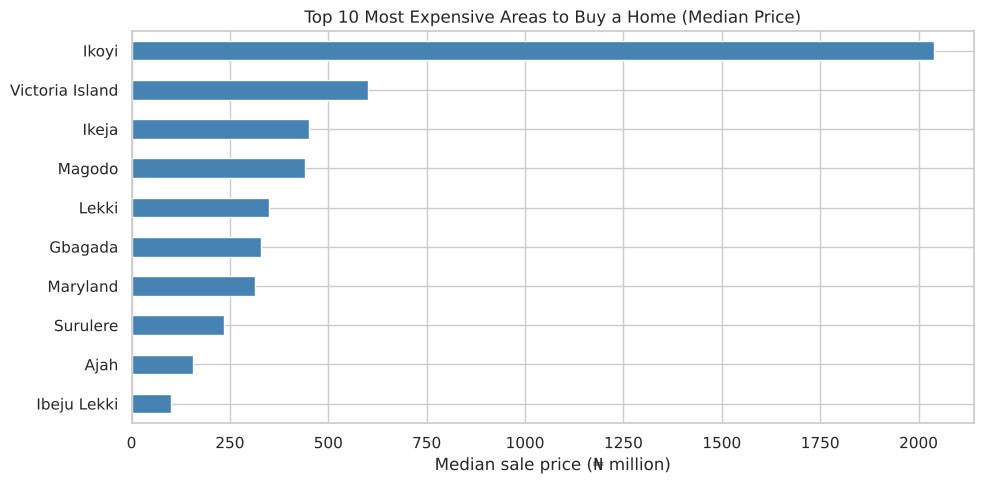

In [17]:
top10 = sale_by_area["median"].head(10).sort_values()
plt.figure()
top10.plot(kind="barh", color="steelblue")
plt.title("Top 10 Most Expensive Areas to Buy a Home (Median Price)")
plt.xlabel("Median sale price (₦ million)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/01_bar_sale_price_by_area.png", dpi=150)
plt.show()

### Chart 2 — Bar chart: median yearly rent by area

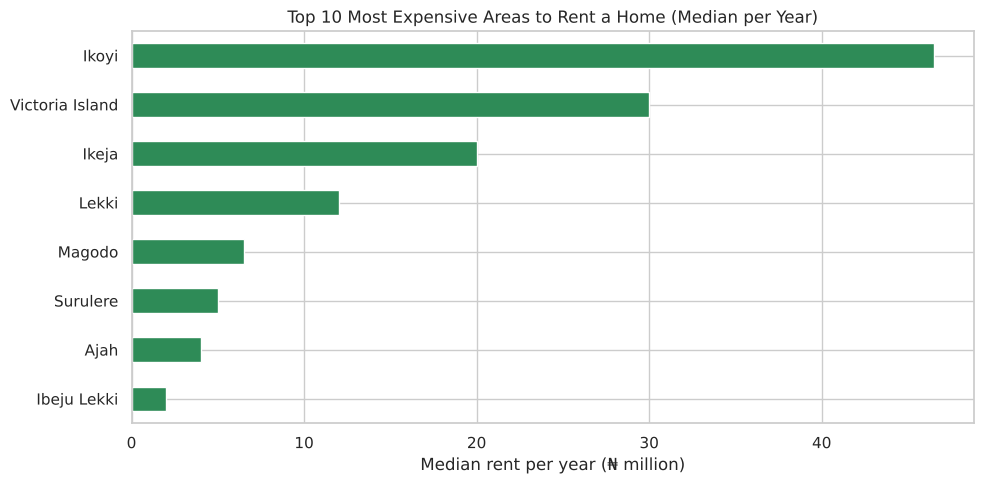

In [18]:
top10_rent = rent_by_area["median"].head(10).sort_values()
plt.figure()
top10_rent.plot(kind="barh", color="seagreen")
plt.title("Top 10 Most Expensive Areas to Rent a Home (Median per Year)")
plt.xlabel("Median rent per year (₦ million)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/02_bar_rent_by_area.png", dpi=150)
plt.show()

### Chart 3 — Column chart: median sale price per bedroom by area
Compares value for money across areas: how much buyers pay for each bedroom.
Uses clean sale listings (no outliers, no multi-unit blocks) in areas with at least 10 sale listings, top 7 areas.
Land and commercial listings have no bedrooms, so they drop out automatically.

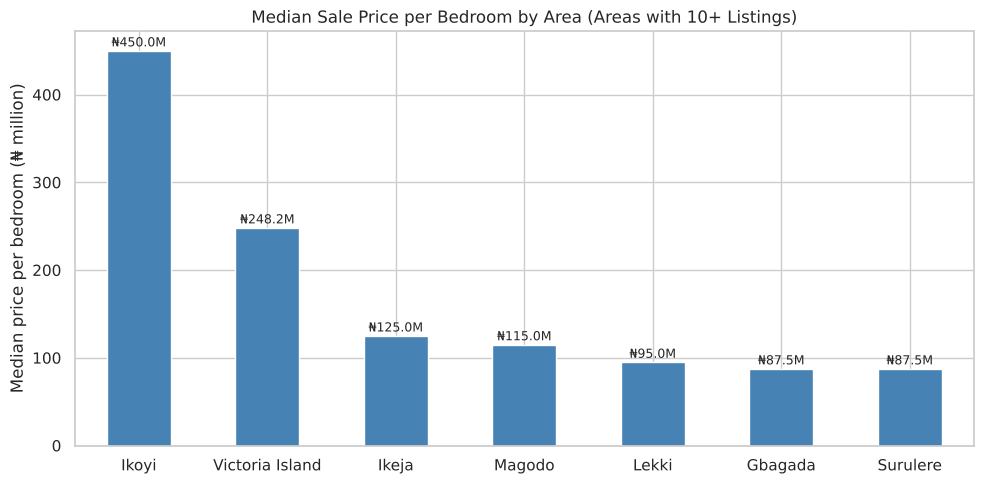

In [19]:
plt.figure()
ax = ppb_by_area.plot(kind="bar", color="steelblue", rot=0)
for i, v in enumerate(ppb_by_area.values):
    ax.text(i, v + 5, f"₦{v:,.1f}M", ha="center", fontsize=9)
plt.title("Median Sale Price per Bedroom by Area (Areas with 10+ Listings)")
plt.xlabel("")
plt.ylabel("Median price per bedroom (₦ million)")
plt.tight_layout()
plt.savefig("charts/03_column_price_per_bedroom_by_area.png", dpi=150)
plt.show()

### Chart 4 — Line chart: price trend by number of bedrooms

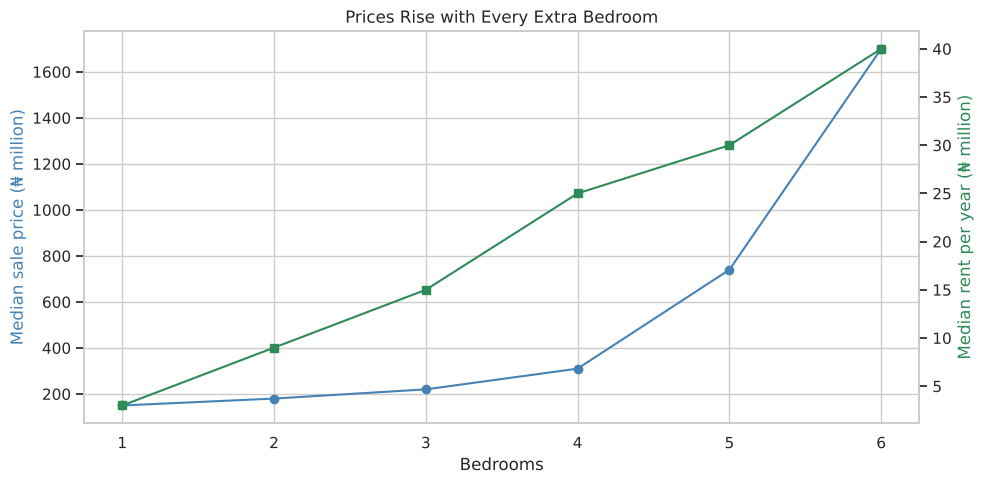

In [20]:
fig, ax1 = plt.subplots()
ax1.plot(beds_trend.index, beds_trend["sale_median_M"], marker="o", color="steelblue", label="Sale price")
ax1.set_xlabel("Bedrooms")
ax1.set_ylabel("Median sale price (₦ million)", color="steelblue")

ax2 = ax1.twinx()   # second y-axis, because rent is much smaller than sale price
ax2.plot(beds_trend.index, beds_trend["rent_median_M"], marker="s", color="seagreen", label="Rent per year")
ax2.set_ylabel("Median rent per year (₦ million)", color="seagreen")
ax2.grid(False)

plt.title("Prices Rise with Every Extra Bedroom")
fig.tight_layout()
plt.savefig("charts/04_line_price_by_bedrooms.png", dpi=150)
plt.show()

### Chart 5 — Scatter plot: rent vs sale price by area (where renting out pays best)
One dot per area: median sale price (x) against median annual rent (y), for residential homes with no outliers or multi-unit blocks.
Only areas with **at least 10 sale and 10 rent listings** are shown, so a single listing cannot distort an area's position.
**Gross rental yield** = median annual rent ÷ median sale price. Dots higher up and further left earn more rent for their price.

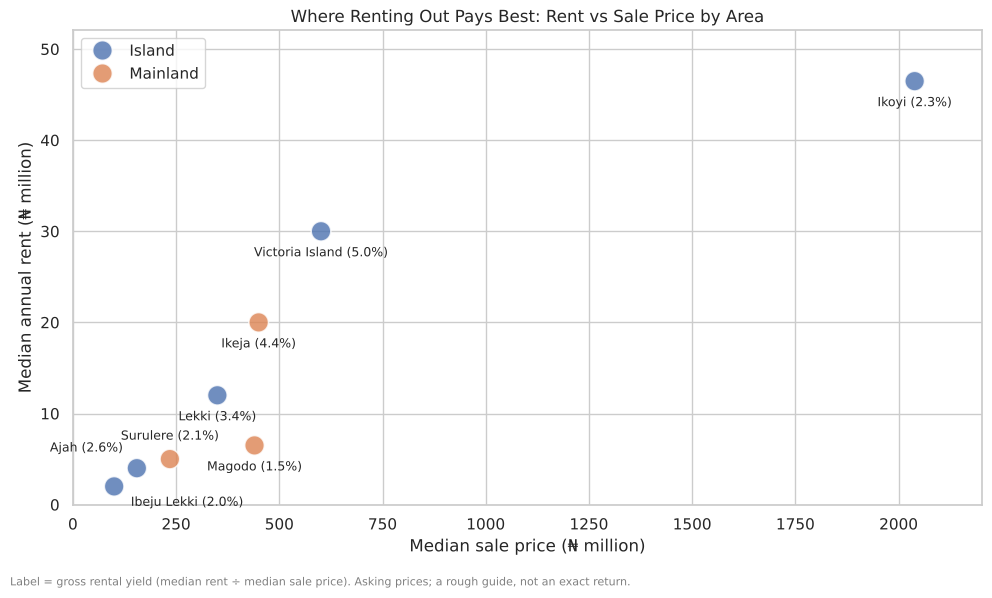

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=yield_by_area, x="sale_median", y="rent_median", hue="region", s=200, alpha=0.8)

offsets = {"Ibeju Lekki": (12, -14, "left"), "Ajah": (-10, 12, "right"), "Surulere": (0, 14, "center")}
for _, row in yield_by_area.iterrows():
    dx, dy, ha = offsets.get(row["area"], (0, -18, "center"))
    plt.annotate(f"{row['area']} ({row['yield_pct']}%)", (row["sale_median"], row["rent_median"]),
                 xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=9)

plt.title("Where Renting Out Pays Best: Rent vs Sale Price by Area")
plt.xlabel("Median sale price (₦ million)")
plt.ylabel("Median annual rent (₦ million)")
plt.xlim(0, yield_by_area["sale_median"].max() * 1.08)
plt.ylim(0, yield_by_area["rent_median"].max() * 1.12)
plt.legend(title="")
plt.figtext(0.01, 0.01, "Label = gross rental yield (median rent ÷ median sale price). Asking prices; a rough guide, not an exact return.",
            fontsize=8, color="gray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("charts/05_scatter_rent_vs_sale_by_area.png", dpi=150)
plt.show()

### Chart 6 — Pie chart: share of listings by property group

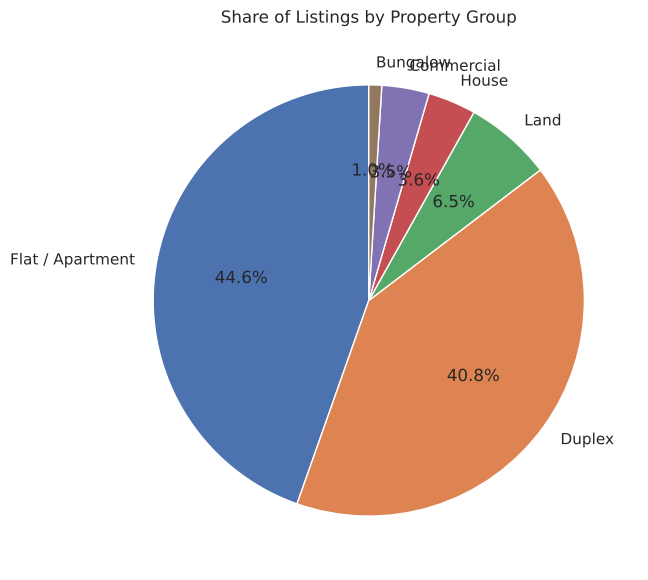

In [22]:
group_counts = df["property_group"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(group_counts, labels=group_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Listings by Property Group")
plt.savefig("charts/06_pie_property_group.png", dpi=150)
plt.show()

### Chart 7 — Heatmap: correlation between numerical columns

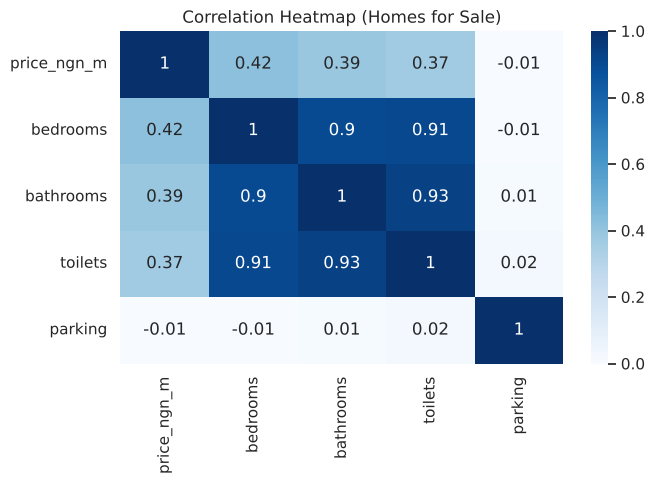

In [23]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=0, vmax=1)
plt.title("Correlation Heatmap (Homes for Sale)")
plt.tight_layout()
plt.savefig("charts/07_heatmap_correlation.png", dpi=150)
plt.show()

### Chart 8 — Histogram: distribution of sale prices

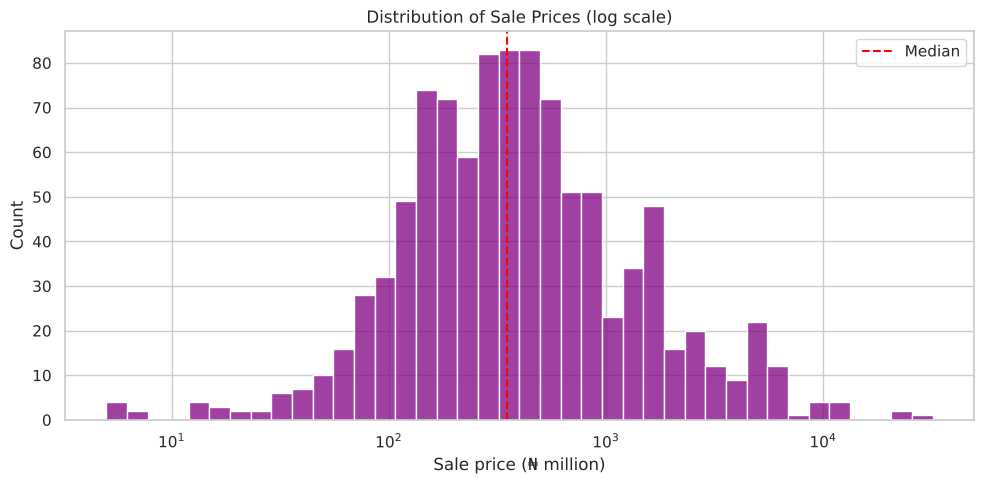

In [24]:
plt.figure()
sns.histplot(sale["price_ngn_m"], bins=40, log_scale=True, color="purple")
plt.axvline(sale["price_ngn_m"].median(), color="red", linestyle="--", label="Median")
plt.title("Distribution of Sale Prices (log scale)")
plt.xlabel("Sale price (₦ million)")
plt.legend()
plt.tight_layout()
plt.savefig("charts/08_histogram_sale_prices.png", dpi=150)
plt.show()

### Chart 9 — Box plot: price spread and outliers by property group

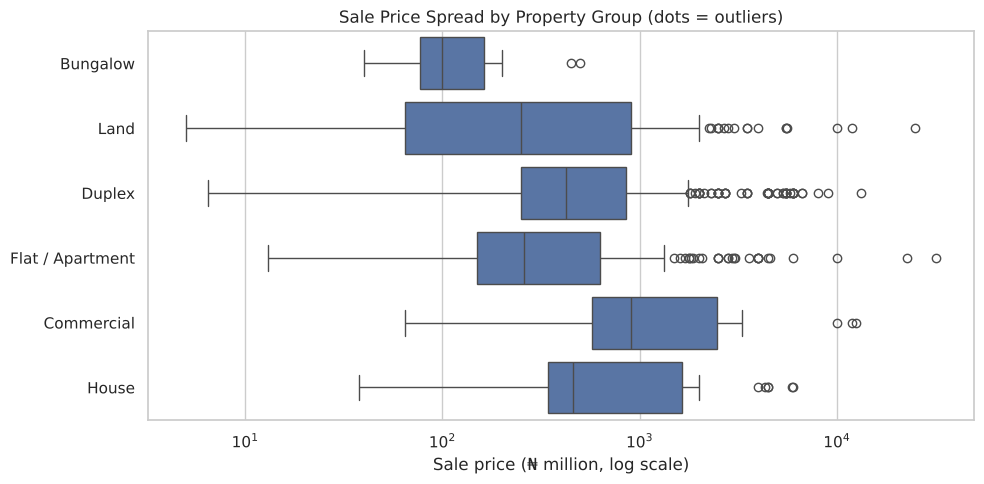

In [25]:
plt.figure()
sns.boxplot(data=sale, x="price_ngn_m", y="property_group")
plt.xscale("log")
plt.title("Sale Price Spread by Property Group (dots = outliers)")
plt.xlabel("Sale price (₦ million, log scale)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/09_boxplot_price_by_group.png", dpi=150)
plt.show()